# **Projectwork 1: Exploring Deep Learning Techniques for Basic Point Cloud Analysis in Environmental Monitoring**

**Specialication:** Digital Environment  
**Authors:** Florian Klaver, Nicola Noger  
**Supervisor:** Martin Schüle  
**Submission Deadline:** 22.05.2025


---
## **Introduction**

The Goal of this project is to develop a Deep learning Model that can classify 3D LiDAR data based on several features. Then the model is deployed on the City-centers of the top five municipalities of the canton zurich with the most residents. In this Jupyter-Notebook, the work-pipeline of the endproduct is shown and described. The data used to train, test and deploy the model on was all collected from "Geoportal Kanton Zürich", the official source for geodata from the canton zurich.

### **Features**
| Field               | Description |
|---------------------|------------|
| **X**              | X coordinate (East-West) in projected coordinate system. |
| **Y**              | Y coordinate (North-South) in projected coordinate system. |
| **Z**              | Elevation (height) above a reference surface. |
| **intensity**      | Strength of the laser return signal. |
| **return_number**  | Order of the return (e.g., first, second, etc.). |
| **number_of_returns** | Total number of returns for a given laser pulse. |
| **synthetic**      | Flag indicating if the point was generated artificially. |
| **key_point**      | Flag for important points (e.g., survey control points). |
| **withheld**       | Flag for points that should be ignored (e.g., noise). |
| **overlap**        | overlap with neighbouring tiles|
| **scanner_channel** | Channel of the scanenr (1 or 2) |
| **scan_direction_flag** | Indicates scanning direction (0 = forward, 1 = backward). |
| **edge_of_flight_line** | Marks if a point is at the edge of a flight path. |
| **user_data**      | Custom field for additional information. |
| **scan_angle** | Angle of the laser scan. |
| **point_source_id** | Identifier for the source of the point (e.g., flight line). |
| **gps_time**       | Timestamp of when the point was captured. |
| **classification** | Category of the point. <br> <br> **1**&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;= Unclassified (e.g. temporary objects such as cars)  <br> **2**&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;= Ground  <br> **3**&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;= Low vegetation (<50cm) <br> **4**&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;= Medium vegetation (0.5m - 3m) <br> **5**&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;= High vegetation (>3m) <br> **6**&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;= Building  <br> **7**&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;= Errorclass/false measurements <br> **15**&nbsp;&nbsp;&nbsp;= High-voltage power lines and antennas  <br>**17**&nbsp;&nbsp;&nbsp;= Bridge  |




---
## **Setup**

In [ ]:
# All imports

import os
import glob
from collections import defaultdict
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import laspy

import tensorflow as tf
from tensorflow.keras import layers, models


from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils.class_weight import compute_class_weight



# Enable vectorized graphics
%config InlineBackend.figure_formats = ["svg"]

# Set seed for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

---
## **Data exploration**

Each data file covering an area 500m x 500m consists of Millions of points (~6-9 Million). Here for the data exploration we only show the content of 1 file to safe computational expenses. For the real data preprocessing and training multiple files were used.

#### Load the data

In [24]:
path_flo = "C:/Users/flori/Desktop/pa-1_data/training/2682000_1248500.laz"
# path_nicola = 

las = laspy.read(path_flo)

# List all available attributes in the LAS file
print("Available attributes in LAZ file:")
for spec in las.point_format.dimension_names:
    print("-", spec)


# total number of points
n_points = len(las.points)
print("\nTotal number of points:", n_points)

print(las.header)
print(las.points)

Available attributes in LAZ file:
- X
- Y
- Z
- intensity
- return_number
- number_of_returns
- synthetic
- key_point
- withheld
- overlap
- scanner_channel
- scan_direction_flag
- edge_of_flight_line
- classification
- user_data
- scan_angle
- point_source_id
- gps_time

Total number of points: 8575878
<LasHeader(1.4, <PointFormat(6, 0 bytes of extra dims)>)>
<ScaleAwarePointRecord(fmt: <PointFormat(6, 0 bytes of extra dims)>, len: 8575878, point size: 30)>


In [25]:
# Inforamtion for transforming the data into a pandas dataframe
print(type(las.x)) 
print(type(las.x[0])) 

<class 'laspy.point.dims.ScaledArrayView'>
<class 'numpy.float64'>


In [26]:
# Create a pandas DataFrame with the LAZ data for initial data exploration
df = pd.DataFrame({
    "X": np.array(las.x), 
    "Y": np.array(las.y),
    "Z": np.array(las.z),
    "intensity": np.array(las.intensity),
    "return_number": np.array(las.return_number),
    "number_of_returns": np.array(las.number_of_returns),
    "synthetic": np.array(las.synthetic),
    "key_point": np.array(las.key_point),
    "withheld": np.array(las.withheld),
    "overlap": np.array(las.overlap),
    "scanner_channel": np.array(las.scanner_channel),
    "scan_direction_flag": np.array(las.scan_direction_flag),
    "edge_of_flight_line": np.array(las.edge_of_flight_line),
    "user_data": np.array(las.user_data),
    "scan_angle": np.array(las.scan_angle),
    "point_source_id": np.array(las.point_source_id),
    "gps_time": np.array(las.gps_time),
    "classification": np.array(las.classification)
})


# get a first impression of the data
print(df.shape)
display(df.info())
display(df.describe())
display(df.head())
print("\nClassification values:")
display(df["classification"].value_counts())

(8575878, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8575878 entries, 0 to 8575877
Data columns (total 18 columns):
 #   Column               Dtype  
---  ------               -----  
 0   X                    float64
 1   Y                    float64
 2   Z                    float64
 3   intensity            uint16 
 4   return_number        uint8  
 5   number_of_returns    uint8  
 6   synthetic            uint8  
 7   key_point            uint8  
 8   withheld             uint8  
 9   overlap              uint8  
 10  scanner_channel      uint8  
 11  scan_direction_flag  uint8  
 12  edge_of_flight_line  uint8  
 13  user_data            uint8  
 14  scan_angle           int16  
 15  point_source_id      uint16 
 16  gps_time             float64
 17  classification       uint8  
dtypes: float64(4), int16(1), uint16(2), uint8(11)
memory usage: 400.8 MB


None

,X,Y,Z,intensity,return_number,number_of_returns,synthetic,key_point,withheld,overlap,scanner_channel,scan_direction_flag,edge_of_flight_line,user_data,scan_angle,point_source_id,gps_time,classification
count,8.575878e+06,8.575878e+06,8.575878e+06,8.575878e+06,8.575878e+06,8.575878e+06,8575878.0,8575878.0,8575878.0,8575878.0,8.575878e+06,8575878.0,8.575878e+06,8.575878e+06,8.575878e+06,8.575878e+06,8.575878e+06,8.575878e+06
mean,2.682246e+06,1.248751e+06,4.120573e+02,4.159468e+04,1.114448e+00,1.226814e+00,0.0,0.0,0.0,0.0,1.492954e+00,0.0,6.296731e-06,1.492954e+00,-2.021756e+03,8.948437e+01,1.763132e+05,3.955130e+00
std,1.381798e+02,1.413980e+02,8.484698e+00,5.978157e+03,3.588130e-01,5.067910e-01,0.0,0.0,0.0,0.0,4.999504e-01,0.0,2.509321e-03,4.999504e-01,7.625772e+02,5.005287e-01,4.868081e+02,2.005045e+00
min,2.682000e+06,1.248500e+06,3.855400e+02,2.335200e+04,1.000000e+00,1.000000e+00,0.0,0.0,0.0,0.0,1.000000e+00,0.0,0.000000e+00,1.000000e+00,-4.333000e+03,8.800000e+01,1.754983e+05,1.000000e+00
25%,2.682131e+06,1.248631e+06,4.050290e+02,3.831600e+04,1.000000e+00,1.000000e+00,0.0,0.0,0.0,0.0,1.000000e+00,0.0,0.000000e+00,1.000000e+00,-2.667000e+03,8.900000e+01,1.758115e+05,2.000000e+00
50%,2.682242e+06,1.248753e+06,4.068400e+02,4.183300e+04,1.000000e+00,1.000000e+00,0.0,0.0,0.0,0.0,1.000000e+00,0.0,0.000000e+00,1.000000e+00,-2.000000e+03,8.900000e+01,1.767797e+05,4.000000e+00
75%,2.682359e+06,1.248873e+06,4.204690e+02,4.554600e+04,1.000000e+00,1.000000e+00,0.0,0.0,0.0,0.0,2.000000e+00,0.0,0.000000e+00,2.000000e+00,-1.500000e+03,9.000000e+01,1.767853e+05,6.000000e+00
max,2.682500e+06,1.249000e+06,4.883700e+02,6.553500e+04,8.000000e+00,8.000000e+00,0.0,0.0,0.0,0.0,2.000000e+00,0.0,1.000000e+00,2.000000e+00,4.833000e+03,9.100000e+01,1.771052e+05,1.500000e+01


,X,Y,Z,intensity,return_number,number_of_returns,synthetic,key_point,withheld,overlap,scanner_channel,scan_direction_flag,edge_of_flight_line,user_data,scan_angle,point_source_id,gps_time,classification
0,2682010.274,1248500.008,406.549,42488,1,1,0,0,0,0,1,0,0,1,-167,90,175812.383225,2
1,2682010.890,1248500.230,406.647,49435,1,1,0,0,0,0,1,0,0,1,-333,90,175812.383227,3
2,2682011.177,1248500.333,406.572,41024,1,1,0,0,0,0,1,0,0,1,-333,90,175812.383227,3
3,2682011.492,1248500.447,406.520,44039,1,1,0,0,0,0,1,0,0,1,-333,90,175812.383228,2
4,2682011.448,1248500.002,406.639,47185,1,1,0,0,0,0,1,0,0,1,-333,90,175812.388767,3



Classification values:


classification
2     3800159
6     3701370
5      506473
1      260685
4      172488
3      100905
7       22814
15      10984
Name: count, dtype: int64

In [27]:
# check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# check for duplicates
print("\nDuplicates:")
print(df.duplicated().sum())


Missing values:
X                      0
Y                      0
Z                      0
intensity              0
return_number          0
number_of_returns      0
synthetic              0
key_point              0
withheld               0
overlap                0
scanner_channel        0
scan_direction_flag    0
edge_of_flight_line    0
user_data              0
scan_angle             0
point_source_id        0
gps_time               0
classification         0
dtype: int64

Duplicates:
0


In [28]:
# check for the number of unique values in each column
print(df.nunique())

X                       500000
Y                       500000
Z                        39119
intensity                 1906
return_number                8
number_of_returns            8
synthetic                    1
key_point                    1
withheld                     1
overlap                      1
scanner_channel              2
scan_direction_flag          1
edge_of_flight_line          2
user_data                    2
scan_angle                  31
point_source_id              4
gps_time               6031230
classification               8
dtype: int64


In [29]:
# Columns with very few unique values can already be dropped sice they do not add any information to the model.
df = df.loc[:, df.nunique() > 4]
print("\nDataFrame after dropping columns with only one unique value:")
display(df.info())

# gps_time most likely also does not add any information to the model.
# We will keep it for now and confirm this assumption later in the analysis.


DataFrame after dropping columns with only one unique value:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8575878 entries, 0 to 8575877
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   X                  float64
 1   Y                  float64
 2   Z                  float64
 3   intensity          uint16 
 4   return_number      uint8  
 5   number_of_returns  uint8  
 6   scan_angle         int16  
 7   gps_time           float64
 8   classification     uint8  
dtypes: float64(4), int16(1), uint16(1), uint8(3)
memory usage: 319.0 MB


None

---
## **Explorative Data Analysis**

#### Class distribution

In [30]:
features = df.drop(columns=["classification"])

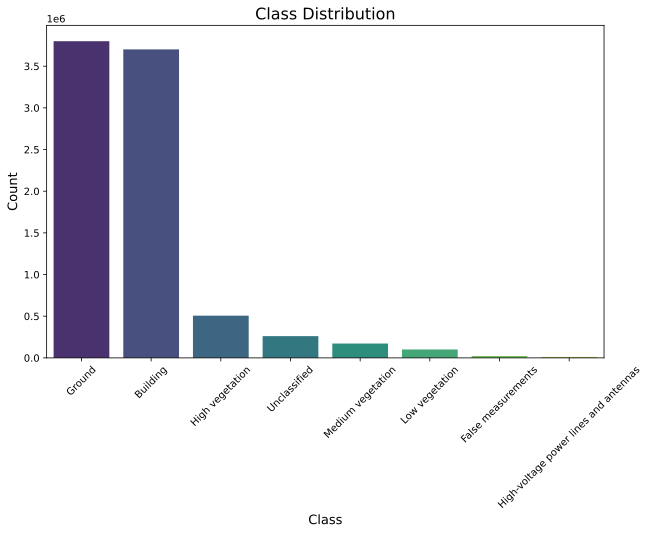

In [31]:
class_labels = {
    1: "Unclassified",
    2: "Ground",
    3: "Low vegetation",
    4: "Medium vegetation",
    5: "High vegetation",
    6: "Building",
    7: "False measurements",
    15: "High-voltage power lines and antennas",
    17: "Bridge"
}

class_counts = df["classification"].value_counts()
class_labels_mapped = class_counts.index.map(class_labels).fillna("Other")

# Plot the class distribution
plt.figure(figsize=(10, 6))
sns.barplot(x=class_labels_mapped, y=class_counts.values, hue=class_labels_mapped, palette="viridis")
plt.title("Class Distribution", fontsize=16)
plt.xlabel("Class", fontsize=13)
plt.ylabel("Count", fontsize=13)
plt.xticks(rotation=45)
plt.show()

#### Histogram

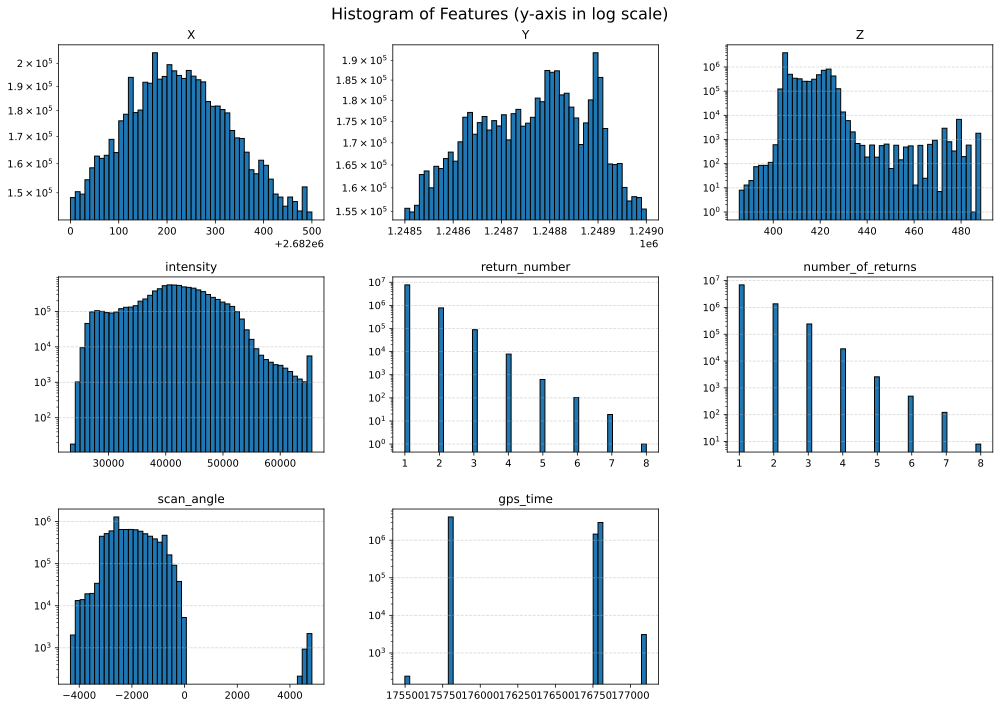

In [32]:
axes = features.hist(figsize=(14, 10), bins=50, edgecolor='black')  
plt.suptitle("Histogram of Features (y-axis in log scale)", fontsize=16)

# Convert axes to a flat list (in case of multiple rows)
axes = axes.flatten()

# Disable x-axis grid and enable y-axis grid
for ax in axes:
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.grid(False, axis='x')
    ax.set_yscale("log")

# Set y-axis to log scale for intensity  
#intensity_index = features.columns.get_loc("intensity")
#axes[intensity_index].set_yscale("log")


plt.tight_layout()
plt.show()

#### Correlation-matrix

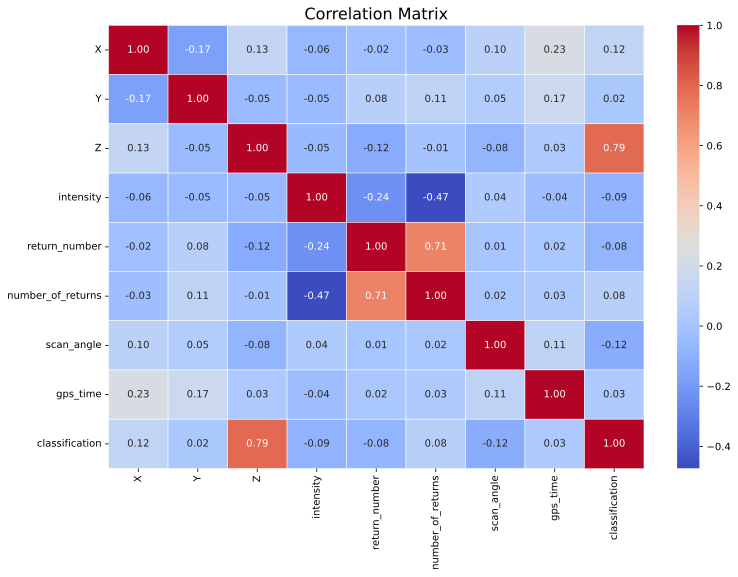

classification       1.000000
Z                    0.790680
X                    0.121682
number_of_returns    0.077915
gps_time             0.030665
Y                    0.024956
return_number       -0.079359
intensity           -0.086007
scan_angle          -0.121207
Name: classification, dtype: float64

In [33]:
corr = df.corr()
f, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(corr, cmap="coolwarm", annot=True, linewidths=0.5, fmt=".2f", ax=ax)
plt.title("Correlation Matrix", fontsize=16)
plt.show()

# print correlation values for classification
display(corr['classification'].sort_values(ascending=False))

---
## **Feature Engineering**

Check feature importance with random forest model to get a general idea which of the remaining features influence the classification the most.

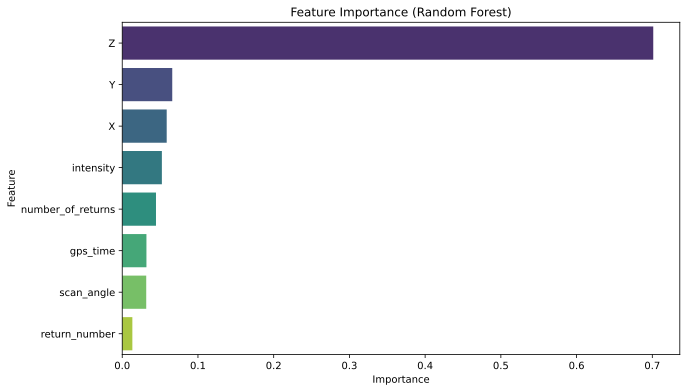

In [34]:
# define features and target
X = df.drop(columns=['classification'])
y = df['classification']

# train random forest
rf = RandomForestClassifier(random_state=42)
rf.fit(X, y)

# extract feature importances
importances = rf.feature_importances_
feature_names = X.columns
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

# sort the features by importance
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# plot the feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis', hue='Feature', legend=False)
plt.title('Feature Importance (Random Forest)')
plt.show()

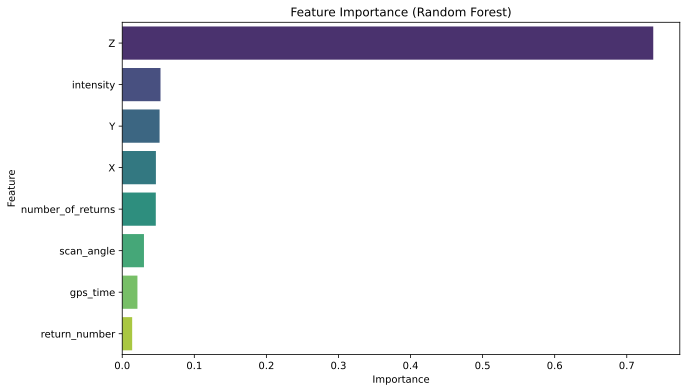

In [35]:
# faster version of the random forest

# define features and target
X = df.drop(columns=['classification'])
y = df['classification']

# train random forest
rf = RandomForestClassifier(n_estimators= 80, max_depth= 20, n_jobs=-1, random_state=42)
X_sample, _, y_sample, _ = train_test_split(X, y, train_size=8000000, stratify=y, random_state=42)
rf.fit(X_sample, y_sample)

# extract feature importances
importances = rf.feature_importances_
feature_names = X.columns
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

# sort the features by importance
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# plot the feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis', hue='Feature', legend=False)
plt.title('Feature Importance (Random Forest)')
plt.show()

---
## **Model Developement**

### PointNet

#### Load training data from multiple files

In [73]:
# === Automatically find all .laz files ===
folder_path = "C:/Users/flori/Desktop/pa-1_data/training"  
file_paths = sorted(glob.glob(os.path.join(folder_path, "*.laz")))
print(f"Found {len(file_paths)} LAZ files.")

# === Prepare containers ===
all_features = []
all_labels = []

# === Create label map based on all files together ===
# (First pass to get all unique labels)
all_labels_raw = []
for path in file_paths:
    las_temp = laspy.read(path)
    all_labels_raw.extend(np.unique(las_temp.classification))

unique_labels = np.unique(all_labels_raw)
# Remove class 7 
unique_labels = unique_labels[unique_labels != 7]

label_map = {label: idx for idx, label in enumerate(unique_labels)}
print("Label Map:", label_map)

# === load and process all files ===
for path in file_paths:
    las = laspy.read(path)


    # Extract features
    ground_height = np.min(las.z)
    X = np.vstack((
        las.x,
        las.y,
        las.z,
        las.intensity,
        las.return_number,
        las.number_of_returns,
        las.z - ground_height,
        las.scan_angle
    )).T.astype(np.float32)

    y_raw = np.array(las.classification)

    # Remove points with class 7 (error class) 
    mask_valid = (y_raw != 7) 
    X = X[mask_valid]
    y_raw = y_raw[mask_valid]

    # map labels
    y_mapped = np.array([label_map[label] for label in y_raw])


    all_features.append(X)
    all_labels.append(y_mapped)

# === Stack everything together ===
X_combined = np.vstack(all_features)
y_combined = np.hstack(all_labels)


print("\n=== Combined dataset ===")
print("X shape:", X_combined.shape)
print("y shape:", y_combined.shape)

# Print class distribution
class_counts = pd.Series(y_combined).value_counts().sort_index()
print("\nClass distribution of combined files:\n")
print(class_counts)

Found 14 LAZ files.
Label Map: {np.uint8(1): 0, np.uint8(2): 1, np.uint8(3): 2, np.uint8(4): 3, np.uint8(5): 4, np.uint8(6): 5, np.uint8(15): 6, np.uint8(17): 7}

=== Combined dataset ===
X shape: (119229651, 8)
y shape: (119229651,)

Class distribution of combined files:

0     3050621
1    71038448
2     1767849
3     3847369
4    14762047
5    23256627
6      148721
7     1357969
Name: count, dtype: int64


#### Preprocessing

In [74]:
def tile_pointclouds(X_all, y_all, coords_all, n_points=1024, block_size=50.0, padding=True):
    """
    Split the combined point cloud into spatial tiles (blocks) of size block_size x block_size,
    then sample exactly n_points per block.

    Parameters:
    - X_all: (N, F) array of features (including x,y,z,...)
    - y_all: (N,) array of integer labels
    - coords_all: (N, 2) array of original (x, y) coordinates in meters
    - n_points: number of points per block
    - block_size: side length of square block in same units as coords (e.g. meters)
    - padding: if True, blocks with fewer than n_points are padded by repeating points;
               if False, they are skipped.

    Returns:
    - X_blocks: (M, n_points, F) array of blocks
    - y_blocks: (M, n_points) array of labels
    """

    # determine tiling extents
    x_min, y_min = coords_all[:,0].min(), coords_all[:,1].min()
    x_max, y_max = coords_all[:,0].max(), coords_all[:,1].max()

    # generate grid of tile origins
    x_edges = np.arange(x_min, x_max, block_size)
    y_edges = np.arange(y_min, y_max, block_size)

    X_list, y_list = [], []
    for xi in x_edges:
        for yi in y_edges:
            # select points within the block
            mask = (
                (coords_all[:,0] >= xi) & (coords_all[:,0] < xi + block_size) &
                (coords_all[:,1] >= yi) & (coords_all[:,1] < yi + block_size)
            )
            idx = np.where(mask)[0]
            if len(idx) == 0:
                continue
            if len(idx) >= n_points:
                chosen = np.random.choice(idx, n_points, replace=False)
            else:
                if not padding:
                    continue
                # pad by repeating random points
                pad_idx = np.random.choice(idx, n_points - len(idx), replace=True)
                chosen = np.concatenate([idx, pad_idx])
            # extract block data
            X_list.append(X_all[chosen])
            y_list.append(y_all[chosen])

    if len(X_list) == 0:
        raise ValueError("No blocks found with the given parameters.")

    X_blocks = np.stack(X_list, axis=0)       # shape (M, n_points, F)
    y_blocks = np.stack(y_list, axis=0)       # shape (M, n_points)
    return X_blocks, y_blocks


# Now X_pointcloud has shape (num_blocks, N_POINTS, F)
# and y_pointcloud has shape (num_blocks, N_POINTS)

In [75]:
X_resampled, y_resampled = X_combined, y_combined
coords_all = X_resampled[:, :2]    # raw x,y in meters

# === Center each point cloud ===
N_POINTS = 1024

# Create blocks:
X_blocks, y_blocks = tile_pointclouds(
    X_all=X_resampled,
    y_all=y_resampled,
    coords_all=coords_all,
    n_points=N_POINTS,
    block_size=50.0,
    padding=True
)

# Center each block in raw x,y,z:
for b in range(X_blocks.shape[0]):
    centroid = X_blocks[b, :, :3].mean(axis=0)  
    X_blocks[b, :, :3] -= centroid


# scale only non spatial features
# split out non-spatial dims (here: dims 3…end)
non_spatial = X_blocks[:, :, 3:]                # shape (M,1024,F-3)
M, P, K = non_spatial.shape
flat = non_spatial.reshape(-1, K)               # shape (M*1024, K)

scaler = StandardScaler()
flat_scaled = scaler.fit_transform(flat)        # fit only on non-spatial

# put them back
X_blocks[:, :, 3:] = flat_scaled.reshape(M, P, K)

X_pointcloud, y_pointcloud = X_blocks, y_blocks


KeyboardInterrupt: 

In [ ]:
# === Train/test split ===
X_train, X_test, y_train, y_test = train_test_split(
    X_pointcloud, y_pointcloud, test_size=0.2, random_state=42
)

# Flatten to 1D: one entry per point
y_train_flat = y_train.flatten()

# Compute a balanced weight for each class index [0..num_classes–1]
classes = np.unique(y_train_flat)
cw = compute_class_weight("balanced", classes=classes, y=y_train_flat)

# Turn into a Tensor so we can look up per-point weights in tf.data
class_weights = tf.constant(cw, dtype=tf.float32)

def attach_weights(X, y):
    # y: (batch, N_POINTS), each entry ∈ [0..num_classes-1]
    w = tf.gather(class_weights, tf.cast(y, tf.int32))  
    # w has same shape as y: one weight per point
    return X, y, w



##### Data augmentation for better generalization

In [ ]:
def random_rotate_pointcloud(batch_pointcloud):
    batch_size = tf.shape(batch_pointcloud)[0]  # <--- use tf.shape
    angles = tf.random.uniform((batch_size,), minval=0, maxval=2 * np.pi)  # np.pi is fine here because it's a float

    cos_vals = tf.cos(angles)
    sin_vals = tf.sin(angles)

    zeros = tf.zeros_like(cos_vals)
    ones = tf.ones_like(cos_vals)

    rotation_matrices = tf.stack([
        tf.stack([cos_vals, -sin_vals, zeros], axis=1),
        tf.stack([sin_vals, cos_vals, zeros], axis=1),
        tf.stack([zeros, zeros, ones], axis=1)
    ], axis=1)  # shape: (batch_size, 3, 3)

    points_xyz = batch_pointcloud[:, :, :3]
    points_rest = batch_pointcloud[:, :, 3:]  # all other features (e.g., intensity, etc.)

    rotated_xyz = tf.matmul(points_xyz, rotation_matrices)
    rotated_pointcloud = tf.concat([rotated_xyz, points_rest], axis=-1)

    return rotated_pointcloud

def jitter_pointcloud(batch_pointcloud, sigma=0.01, clip=0.05):
    jitter = tf.clip_by_value(
        sigma * tf.random.normal(tf.shape(batch_pointcloud)),
        -clip,
        clip
    )
    return batch_pointcloud + jitter

def augment_fn(X, y):
    X = random_rotate_pointcloud(X)
    X = jitter_pointcloud(X)
    return X, y

##### Create Tensorflow Datasets

In [ ]:
# --- Training dataset: shuffle, augment, batch, attach weights ---
train_dataset = (
    tf.data.Dataset
      .from_tensor_slices((X_train, y_train))
      .shuffle(1024, seed=42)
      .map(augment_fn, num_parallel_calls=tf.data.AUTOTUNE)
      .batch(64)
      .map(attach_weights, num_parallel_calls=tf.data.AUTOTUNE)
      .prefetch(tf.data.AUTOTUNE)
)

# --- Validation dataset: no augmentation, but still attach weights ---
test_dataset = (
    tf.data.Dataset
      .from_tensor_slices((X_test, y_test))
      .batch(64)
      .map(attach_weights, num_parallel_calls=tf.data.AUTOTUNE)
      .prefetch(tf.data.AUTOTUNE)
)


#### PointNet Model 

In [ ]:
class OrthogonalRegularizer(layers.Layer):
    """Adds orthogonality regularization for a (batch, k, k) matrix."""
    def __init__(self, reg_weight=1e-3, **kwargs):
        super().__init__(**kwargs)
        self.reg_weight = reg_weight

    def call(self, matrix):
        # matrix: (batch, k, k)
        # compute A * A^T
        aat = tf.matmul(matrix, tf.transpose(matrix, perm=[0, 2, 1]))
        # identity (k, k) where k = matrix.shape[-1]
        k = tf.shape(matrix)[1]
        I = tf.eye(k, dtype=matrix.dtype)
        # loss = mean squared Frobenius norm of (A A^T - I)
        loss = tf.reduce_mean(tf.square(aat - I))
        self.add_loss(self.reg_weight * loss)
        return matrix

def tnet(inputs, k, name):
    x = layers.Conv1D(64, 1, use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv1D(128, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv1D(1024, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.GlobalMaxPooling1D()(x)
    x = layers.Dense(512, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Dense(256, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    # initialize to identity bias
    bias_init = tf.keras.initializers.Constant(np.eye(k).flatten())
    x = layers.Dense(
        k * k,
        kernel_initializer='zeros',
        bias_initializer=bias_init,
        name=f"{name}_fc_transform"
    )(x)
    # reshape to (k, k)
    x = layers.Reshape((k, k), name=f"{name}_reshape")(x)
    # apply orthogonal regularization
    return OrthogonalRegularizer(name=f"{name}_orthoreg")(x)

def build_pointnet_model(num_points, num_features, num_classes):
    inputs = tf.keras.Input(shape=(num_points, num_features))

    # Input T-Net
    input_transform = tnet(inputs, num_features, name="input_tnet")
    x = layers.Lambda(lambda args: tf.matmul(args[0], args[1]))(
        [inputs, input_transform])

    # Per-point MLP
    x = layers.Conv1D(64, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv1D(64, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # Feature T-Net
    feature_transform = tnet(x, 64, name="feature_tnet")
    x = layers.Lambda(lambda args: tf.matmul(args[0], args[1]))(
        [x, feature_transform])

    # Deeper per-point MLP
    x = layers.Conv1D(64, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv1D(128, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv1D(1024, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # Global feature
    global_feat = layers.GlobalMaxPooling1D()(x)

    # Segmentation head
    global_feat_repeated = layers.RepeatVector(num_points)(global_feat)
    concat = layers.Concatenate()([x, global_feat_repeated])

    x = layers.Conv1D(512, 1, use_bias=False)(concat)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv1D(256, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv1D(128, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Conv1D(num_classes, 1, activation='softmax')(x)

    return models.Model(inputs=inputs, outputs=outputs, name="PointNet_Segmentation")


In [ ]:
NUM_CLASSES = len(np.unique(y_pointcloud))
model = build_pointnet_model(num_points=N_POINTS, num_features=X_pointcloud.shape[2], num_classes=NUM_CLASSES)

model.summary()


model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005),
    metrics=['accuracy', 
             tf.keras.metrics.MeanIoU(num_classes=NUM_CLASSES, name='mean_iou')
             ]
)

Model: "PointNet_Segmentation"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 1024, 8)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_41 (Conv1D)  │ (None, 1024, 64)  │        512 │ input_layer_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1024, 64)  │        256 │ conv1d_41[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_41 (ReLU)     │ (None, 1024, 64)  │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_42 (Conv1D)  │ (None, 1024, 128) │      8,192 │ re_lu_41[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1024, 128) │        512 │ conv1d_42[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_42 (ReLU)     │ (None, 1024, 128) │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_43 (Conv1D)  │ (None, 1024,      │    131,072 │ re_lu_42[0][0]    │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1024,      │      4,096 │ conv1d_43[0][0]   │
│ (BatchNormalizatio… │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_43 (ReLU)     │ (None, 1024,      │          0 │ batch_normalizat… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 1024)      │          0 │ re_lu_43[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 512)       │    524,288 │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512)       │      2,048 │ dense_10[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_44 (ReLU)     │ (None, 512)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 256)       │    131,072 │ re_lu_44[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_11[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_45 (ReLU)     │ (None, 256)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_tnet_fc_tran… │ (None, 64)        │     16,448 │ re_lu_45[0][0]    │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_tnet_reshape  │ (None, 8, 8)      │          0 │ input_tnet_fc_tr… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 4,049,224 (15.45 MB)

 Trainable params: 4,036,808 (15.40 MB)

 Non-trainable params: 12,416 (48.50 KB)

##### Callbacks and training

In [ ]:
# define callbacks
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.5, 
    patience=5, 
    min_lr=1e-6,
    verbose=1
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=100,
    callbacks=[reduce_lr, early_stop]
)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 139s 5s/step - accuracy: 0.2496 - loss: 2.1060 - val_accuracy: 0.2702 - val_loss: 2.0498 - learning_rate: 5.0000e-04
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 64s 5s/step - accuracy: 0.4095 - loss: 1.6137 - val_accuracy: 0.2890 - val_loss: 1.9912 - learning_rate: 5.0000e-04
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 62s 5s/step - accuracy: 0.4488 - loss: 1.4899 - val_accuracy: 0.2803 - val_loss: 1.9449 - learning_rate: 5.0000e-04
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 62s 5s/step - accuracy: 0.4809 - loss: 1.3980 - val_accuracy: 0.2323 - val_loss: 1.9361 - learning_rate: 5.0000e-04
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 62s 5s/step - accuracy: 0.5057 - loss: 1.3284 - val_accuracy: 0.2487 - val_loss: 1.9500 - learning_rate: 5.0000e-04
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 62s 5s/step - accuracy: 0.5251 - loss: 1.2751 - val_accuracy: 0.2203 - val_loss: 1.9068 - learning_rate: 5.0000e-04
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 62s 5s/step - accuracy: 0.5420

##### Visualize training process

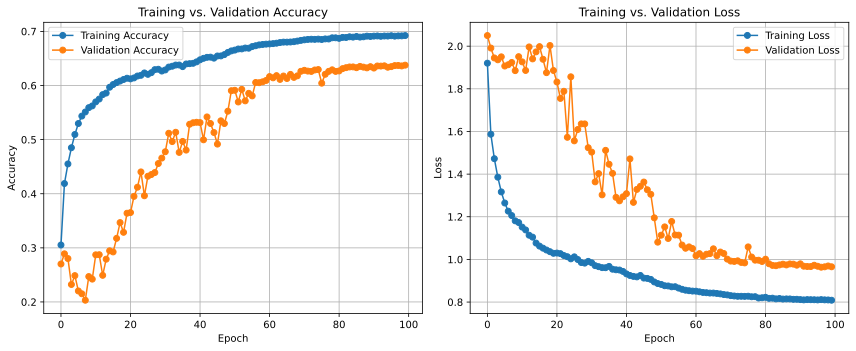

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='o')
plt.title('Training vs. Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', marker='o')
plt.plot(epochs_range, val_loss, label='Validation Loss', marker='o')
plt.title('Training vs. Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

#### Evaluation

In [ ]:
# Predict on test set
y_pred = model.predict(X_test)
y_pred_labels = np.argmax(y_pred, axis=-1)

# Flatten for evaluation
y_true_flat = y_test.flatten()
y_pred_flat = y_pred_labels.flatten()

print("Accuracy:", accuracy_score(y_true_flat, y_pred_flat))
print(classification_report(y_true_flat, y_pred_flat))


1636/1636 ━━━━━━━━━━━━━━━━━━━━ 668s 408ms/step
Accuracy: 0.455233131365973
              precision    recall  f1-score   support

           0       0.07      0.03      0.04   1502168
           1       0.81      0.64      0.72  33297192
           2       0.01      0.23      0.03    745571
           3       0.13      0.05      0.07   1045366
           4       0.51      0.19      0.27   1904797
           5       0.83      0.16      0.27  14811863
           6       0.00      0.00      0.00     89933
           7       0.00      0.18      0.01    188006

    accuracy                           0.46  53584896
   macro avg       0.30      0.19      0.18  53584896
weighted avg       0.75      0.46      0.53  53584896



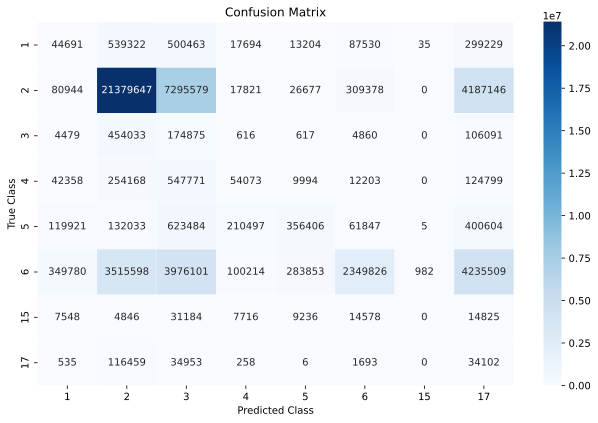

In [ ]:
# Flatten labels
y_true = y_test.flatten()
y_pred_flat = y_pred_labels.flatten()

# Get inverse label map for display
inv_label_map = {v: k for k, v in label_map.items()}
labels = sorted(inv_label_map.keys())

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred_flat, labels=labels)

# Plot
plt.figure(figsize=(9, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[f"{inv_label_map[i]}" for i in labels],
            yticklabels=[f"{inv_label_map[i]}" for i in labels])
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.show()

### PointNet++

---
## **Model Deployment**

#### Prepare functions to deploy model on all Municipalities

In [ ]:
def load_city_blocks(
    municipality_name: str,
    base_folder: str = r"C:/Users/flori/Desktop/pa-1_data/clipped_files",
    N_POINTS: int = 1024,
    scaler=None,
    label_map: dict = None
):
    """
    Liest alle .laz in base_folder/municipality_name ein, extrahiert Features und Labels,
    splittet in Blöcke zu je N_POINTS, zentriert und skaliert sie.

    Args:
        municipality_name: Name des Unterordners mit den Test-Files.
        base_folder: Pfad zum Ordner, der alle Städte-Ordner enthält.
        N_POINTS: Anzahl Punkte pro Block.
        scaler: ein fitted sklearn-Scaler (z.B. StandardScaler).
        label_map: Dict mapping original_class -> target_index.

    Returns:
        X_test: np.array, Form (total_blocks, N_POINTS, n_features)
        y_test: np.array, Form (total_blocks, N_POINTS)
    """
    if scaler is None or label_map is None:
        raise ValueError("Bitte 'scaler' und 'label_map' übergeben.")

    city_folder = os.path.join(base_folder, municipality_name)
    file_paths = glob.glob(os.path.join(city_folder, "*.laz"))
    print(f"Gefundene Test-Dateien in {municipality_name}: {len(file_paths)}")

    all_blocks = []
    all_labels = []

    for path in file_paths:
        las = laspy.read(path)
        print(f"  -> verarbeite {os.path.basename(path)}")

        # Feature-Extraktion
        ground_h = np.min(las.z)
        feats = np.vstack((
            las.x,
            las.y,
            las.z,
            las.intensity,
            las.return_number,
            las.number_of_returns,
            las.z - ground_h,
            las.scan_angle
        )).T.astype(np.float32)

        # Label mapping und Filter
        y_raw = np.array(las.classification)
        y_mapped = np.array([label_map.get(c, -1) for c in y_raw], dtype=np.int32)
        mask = (y_mapped != -1)
        feats = feats[mask]
        y_mapped = y_mapped[mask]

        # Skalieren
        X_scaled = scaler.transform(feats)

        # Split in Blöcke
        n_blocks = len(X_scaled) // N_POINTS
        if n_blocks == 0:
            continue

        X_trim = X_scaled[: n_blocks * N_POINTS]
        y_trim = y_mapped[: n_blocks * N_POINTS]

        X_blocks = X_trim.reshape(n_blocks, N_POINTS, -1)
        y_blocks = y_trim.reshape(n_blocks, N_POINTS)

        # Zentrieren
        centroids = X_blocks[:, :, :3].mean(axis=1, keepdims=True)
        X_blocks[:, :, :3] -= centroids

        all_blocks.append(X_blocks)
        all_labels.append(y_blocks)

    if not all_blocks:
        print("Keine Blöcke gefunden.")
        return np.empty((0, N_POINTS, feats.shape[1])), np.empty((0, N_POINTS), dtype=int)

    X_test = np.concatenate(all_blocks, axis=0)
    y_test = np.concatenate(all_labels, axis=0)
    print(f"Gesamtzahl Test-Blöcke für {municipality_name}: {X_test.shape[0]}")

    return X_test, y_test



In [ ]:
def evaluate_city(municipality_name, X_test, y_test, model, label_map):
    """
    Macht Modell-Vorhersage auf X_test, rechnet Metriken aus
    und plottet die Konfusionsmatrix für die gegebene Stadt.
    """
    if X_test.shape[0] == 0:
        print(f"\n=== {municipality_name}: keine Test-Blöcke gefunden. ===")
        return

    # 1) Vorhersage
    y_pred_probs = model.predict(X_test, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=-1)

    # 2) Flach auswerten
    y_true_flat = y_test.flatten()
    y_pred_flat = y_pred.flatten()

    print(f"\n=== Auswertung für {municipality_name} ===")
    acc = accuracy_score(y_true_flat, y_pred_flat)
    print(f"Accuracy: {acc:.4f}\n")
    print("Classification Report:")
    print(classification_report(y_true_flat, y_pred_flat, digits=4))

    # 3) Konfusionsmatrix
    inv_label_map = {v: k for k, v in label_map.items()}
    labels = sorted(inv_label_map.keys())
    cm = confusion_matrix(y_true_flat, y_pred_flat, labels=labels)

    plt.figure(figsize=(9, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=[inv_label_map[i] for i in labels],
        yticklabels=[inv_label_map[i] for i in labels]
    )
    plt.title(f"Confusion Matrix – {municipality_name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")
    plt.tight_layout()
    plt.show()


#### Deploy Model on the prepared clipped files with the funtions

##### Dietikon

Gefundene Test-Dateien in Dietikon: 18
  -> verarbeite 2671000_1251500_cropped.laz
  -> verarbeite 2671500_1251000_cropped.laz
  -> verarbeite 2671500_1251500_cropped.laz
  -> verarbeite 2671500_1252000_cropped.laz
  -> verarbeite 2671500_1252500_cropped.laz
  -> verarbeite 2672000_1250500_cropped.laz
  -> verarbeite 2672000_1251000_cropped.laz
  -> verarbeite 2672000_1251500_cropped.laz
  -> verarbeite 2672000_1252000_cropped.laz
  -> verarbeite 2672000_1252500_cropped.laz
  -> verarbeite 2672500_1250500_cropped.laz
  -> verarbeite 2672500_1251000_cropped.laz
  -> verarbeite 2672500_1251500_cropped.laz
  -> verarbeite 2672500_1252000_cropped.laz
  -> verarbeite 2672500_1252500_cropped.laz
  -> verarbeite 2673000_1250500_cropped.laz
  -> verarbeite 2673000_1251000_cropped.laz
  -> verarbeite 2673000_1251500_cropped.laz
Gesamtzahl Test-Blöcke für Dietikon: 52329

=== Auswertung für Dietikon ===
Accuracy: 0.4552

Classification Report:
              precision    recall  f1-score   suppor

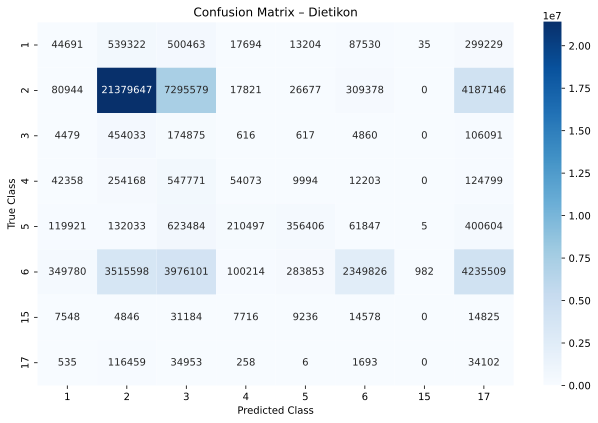

In [ ]:
X_test, y_test = load_city_blocks(municipality_name="Dietikon", scaler=scaler, label_map=label_map)

evaluate_city(
    municipality_name="Dietikon",
    X_test=X_test,
    y_test=y_test,
    model=model,
    label_map=label_map
)